# WeVisOne-VL-4B：停车场复杂几何理解测试

**实验目的**：与 `xiaomi-lens-0 测试v2.0.ipynb` 及 `qwen3.5-4B_停车场几何测试v2.0.ipynb` 对照。以下 `FRAME` 与六组题目的**英文提示词完全照抄 Qwen 版本**，输入同为停车场图1和图2。绝不在正式对比里为腾讯模型改写问题。

**腾讯模型**：`tencent/WeVisOne-VL-4B`，按仓库已经配置的 `wevisone-vl` 环境、官方 `WeVisOneVL` 接口运行。`task="freeform", prompt=question` 将**完整原题**直接交给模型，允许其按实际能力输出 BBox 与 Mask。

**不可直接比较的地方**：腾讯官方推理 API 和所用模型未提供与 Xiaomi/Qwen 对应的 `enable_thinking=True/False` 切换。为保证六项实验排列一致，Thinking=True 的单元格保留**同一提示词**但明确标记 **N/A（不执行，不计失败）**，不伪造“开启思考”。本 Notebook 实际有效测试为 ①②③关闭思考④关闭思考，共四次。

**输出**：模型原始回复在图外展示；图中仅绘制去重后的短编号定位框。测试1/3默认只突出目标框，测试2展示所有不重复的框。仅在模型实际生成 `<OBJ>` 时解码并叠加 Mask。对于未返回结构化框或 Mask 的情况，如实标记，不用后处理检测器补框。正式测试默认贪心解码，`max_new_tokens=8192`，`repetition_penalty=1.0`，尽量接近先前 Qwen 的生成设置。


In [1]:
import sys
import re
import time
from pathlib import Path

import torch
from PIL import Image, ImageDraw
from IPython.display import display

# 兼容从仓库根目录 / evaluation / Notebook 所在目录启动
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "datasets/几何简单测试").is_dir()), None)
assert ROOT is not None, "未找到 VLM-test 项目根目录，请检查 Notebook 的工作目录"

# 若未通过 pip 安装，优先允许使用仓库内的腾讯官方代码
TENCENT_ROOT = ROOT / "models" / "WeVisOne-VL"
if TENCENT_ROOT.is_dir() and str(TENCENT_ROOT) not in sys.path:
    sys.path.insert(0, str(TENCENT_ROOT))

from wevisone_vl import WeVisOneVL
from wevisone_vl.visualization import render_overlay, parse_predictions

# 优先加载仓库里完整的本地 4B 权重；不存在则走 HF 模型 ID
LOCAL_CKPT = TENCENT_ROOT / "checkpoints" / "WeVisOne-VL-4B"
if (LOCAL_CKPT / "config.json").is_file() and (LOCAL_CKPT / "mask_decoder.pt").is_file():
    MODEL_PATH = str(LOCAL_CKPT)
else:
    MODEL_PATH = "tencent/WeVisOne-VL-4B"

# 与 Qwen 的像素范围尽量对齐，但不是等价的视觉编码器
model = WeVisOneVL(
    MODEL_PATH,
    backend="transformers",
    device="auto",
    dtype="bfloat16",
    min_pixels=224 * 224,
    max_pixels=2048 * 2048,
    attention_implementation="sdpa",
)

print("模型:", MODEL_PATH)
print("数据集根目录:", ROOT)
print("CUDA 可用:", torch.cuda.is_available())
print("注意：WeVisOne-VL 官方 API 没有 enable_thinking 模式切换")


/home/20261024_1/.local/share/mamba/envs/wevisone-vl/lib/python3.12/site-packages/supervision/annotators/core.py:12: UserWarning: OpenCV (`opencv-python`) is not installed; supervision is using its pure NumPy fallback backend instead. Some operations may be slower or behave slightly differently. Install `opencv-python` for full performance and compatibility.
  from supervision import _cv2 as cv2
/home/20261024_1/.local/share/mamba/envs/wevisone-vl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 714/714 [00:00<00:00, 10838.03it/s]


模型: tencent/WeVisOne-VL-4B
数据集根目录: /home/20261024_1/Workspace/qyh/VLM-test
CUDA 可用: True
注意：WeVisOne-VL 官方 API 没有 enable_thinking 模式切换


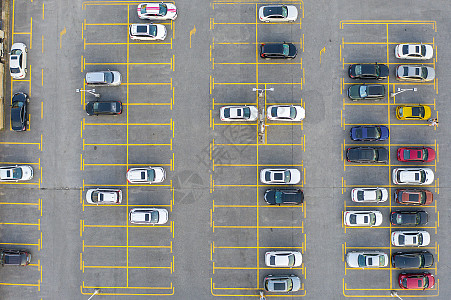

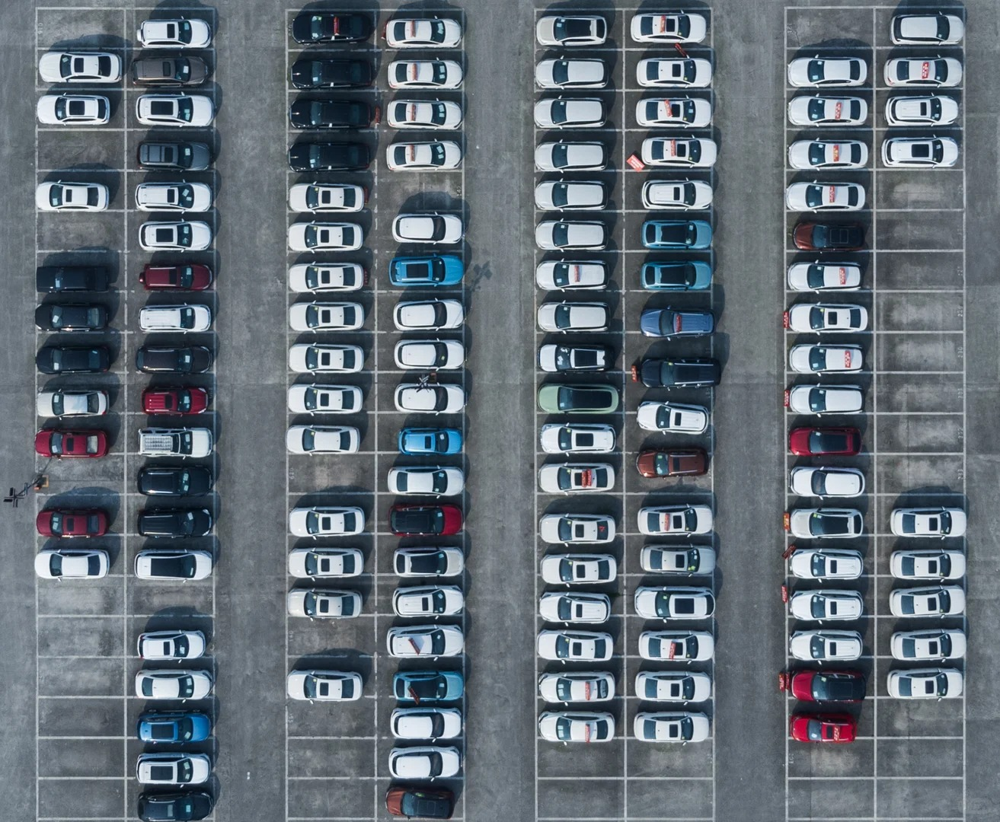

In [2]:
DATA_DIR = ROOT / "datasets/几何简单测试"

img1 = Image.open(DATA_DIR / "停车场图1.png").convert("RGB")
img2 = Image.open(DATA_DIR / "停车场图2.jpg").convert("RGB")

display(img1, img2)

In [3]:
# 仅修复解析与可视化，不修改任何测试题目或模型推理参数。
# 不再使用官方 render_overlay：其默认会在图上写完整的 <ref> 文本标签。
# 默认策略：测试1/3只画目标框；测试2画去重后的全部框；测试4画前两个候选框。

import numpy as np
from PIL import ImageFont

RUN_HISTORY = globals().get("RUN_HISTORY", [])
MAX_RESPONSE_PRINT_CHARS = 8000
COLORS = [
    (0, 255, 85), (255, 150, 0), (0, 210, 255),
    (255, 60, 100), (255, 220, 0), (210, 120, 255),
]


def _records_from_result(image, result):
    """把输出转换为原始框列表：标签用于记录，不写到图上。"""
    w, h = image.size
    parsed = parse_predictions(result.response or "", w, h)
    records = []
    for label, ann_list in parsed.items():
        for ann in ann_list:
            if ann.get("type") == "box":
                xyxy = [float(v) for v in ann["coords"]]
                if xyxy[0] < xyxy[2] and xyxy[1] < xyxy[3]:
                    records.append({"label": label, "xyxy": xyxy})

    # 官方 parse_predictions 需要 <ref> 标签；兼容仅包含 <box> 的输出。
    if not records:
        for match in re.finditer(
            r"<box>(.*?)(?:</box>|$)", result.response or "", flags=re.I | re.S
        ):
            values = [int(v) for v in re.findall(r"<(\d{1,4})>", match.group(1))]
            for off in range(0, len(values) - 3, 4):
                x1, y1, x2, y2 = values[off:off + 4]
                if 0 <= x1 < x2 <= 1000 and 0 <= y1 < y2 <= 1000:
                    records.append({
                        "label": f"box_{len(records) + 1}",
                        "xyxy": [x1*w/1000, y1*h/1000, x2*w/1000, y2*h/1000],
                    })

    # 兼容文本式 bbox=[x1,y1,x2,y2]。
    if not records:
        for match in re.finditer(
            r"(?:bbox_2d|bbox|box)\s*[:：=]\s*\[([^\]]+)\]",
            result.response or "", flags=re.I
        ):
            nums = [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", match.group(1))]
            if len(nums) != 4:
                continue
            if all(0 <= v <= 1 for v in nums):
                nums = [v * 1000 for v in nums]
            x1, y1, x2, y2 = nums
            if 0 <= x1 < x2 <= 1000 and 0 <= y1 < y2 <= 1000:
                records.append({
                    "label": f"box_{len(records) + 1}",
                    "xyxy": [x1*w/1000, y1*h/1000, x2*w/1000, y2*h/1000],
                })

    # result.boxes 是专用像素解码器返回的归一化框。
    for index, box in enumerate(result.boxes):
        if len(box) != 4:
            continue
        xyxy = [float(box[0])*w, float(box[1])*h,
                float(box[2])*w, float(box[3])*h]
        if xyxy[0] < xyxy[2] and xyxy[1] < xyxy[3]:
            records.append({"label": f"mask_{index+1}", "xyxy": xyxy})
    return records


def _box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    overlap = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return overlap / (area_a + area_b - overlap + 1e-9)


def _unique_records(records, iou_threshold=0.98):
    """只删除几乎相同的重复框，不合并相邻车辆。保留第一次出现的标签。"""
    unique = []
    for record in records:
        if not any(_box_iou(record["xyxy"], x["xyxy"]) >= iou_threshold
                   for x in unique):
            unique.append(record)
    return unique


def _select_visible_records(records, question, labels=None, show_all=False):
    """画哪些框属于显示策略，而不是修改模型预测。"""
    if show_all:
        return records
    if labels:   # 测试4：按模型原始输出顺序展示前两个候选，语义须人工核对
        return records[:len(labels)]
    if "find all cars" in question.lower():  # 测试2
        return records
    return records[:1]  # 测试1 / 测试3：突出主要目标


def _load_font(size):
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            pass
    return ImageFont.load_default()


def _mask_overlay(image, result, selected):
    """仅绘制与当前显示框匹配的真实 Mask，不绘制人工伪造的 Mask。"""
    if not result.masks:
        return image.copy(), 0
    w, h = image.size
    selected_ids = []
    if result.boxes:
        for record in selected:
            best_i, best_iou = None, 0.0
            for i, box in enumerate(result.boxes):
                if i >= len(result.masks) or len(box) != 4:
                    continue
                xyxy = [float(box[0])*w, float(box[1])*h,
                        float(box[2])*w, float(box[3])*h]
                iou = _box_iou(record["xyxy"], xyxy)
                if iou > best_iou:
                    best_i, best_iou = i, iou
            if best_i is not None and best_iou > 0.8 and best_i not in selected_ids:
                selected_ids.append(best_i)
    elif not selected:
        selected_ids = list(range(len(result.masks)))

    # 没有可靠的框到 Mask 对应关系时，不瞎配颜色或涂抹。
    if not selected_ids:
        return image.copy(), 0

    canvas = np.asarray(image.convert("RGB"), dtype=np.float32).copy()
    for k, i in enumerate(selected_ids):
        alpha = np.asarray(result.masks[i], dtype=np.float32)
        if alpha.ndim == 3:
            alpha = np.squeeze(alpha)
        if alpha.ndim != 2:
            continue
        if alpha.shape != (h, w):
            alpha = np.asarray(
                Image.fromarray(np.uint8(np.clip(alpha, 0, 1)*255)).resize(
                    (w, h), Image.Resampling.BILINEAR
                ), dtype=np.float32
            ) / 255.0
        active = np.clip(alpha, 0, 1) >= 0.5
        color = np.array(COLORS[k % len(COLORS)], dtype=np.float32)
        canvas[active] = 0.55 * canvas[active] + 0.45 * color
    return Image.fromarray(np.uint8(np.clip(canvas, 0, 255))), len(selected_ids)


def _display_result(image, result, records, question, labels=None,
                    show_all=False, save_path=None):
    """不画任何长文本！只画细框和短编号，完整标签留在下方文字输出。"""
    unique = _unique_records(records)
    visible = _select_visible_records(unique, question, labels=labels,
                                     show_all=show_all)
    canvas, shown_masks = _mask_overlay(image, result, visible)
    draw = ImageDraw.Draw(canvas)
    w, h = image.size
    line_width = max(2, round(min(w, h) / 250))
    font = _load_font(max(11, round(min(w, h) / 48)))

    for i, record in enumerate(visible):
        x1, y1, x2, y2 = record["xyxy"]
        color = COLORS[i % len(COLORS)]
        draw.rectangle((x1, y1, x2, y2), outline=color, width=line_width)
        # 只有单个数字或 A/B，绝不使用 <ref> 中的长句作为标签。
        short = str(labels[i]) if labels and i < len(labels) else str(i+1)
        left, top = max(0, int(x1)), max(0, int(y1))
        bbox = draw.textbbox((0, 0), short, font=font)
        text_w = bbox[2] - bbox[0]
        text_h = bbox[3] - bbox[1]
        rect = (left, top, min(w, left+text_w+8), min(h, top+text_h+8))
        draw.rectangle(rect, fill=(0, 0, 0))
        draw.text((left+4, top+2-bbox[1]), short, fill=color, font=font)

    display(canvas)
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        canvas.save(path)
        print("可视化图片已保存：", path)

    print(f"模型原始框数：{len(records)} | 去重后：{len(unique)} "
          f"| 当前显示：{len(visible)} | 原始 Mask：{len(result.masks)} "
          f"| 本图显示 Mask：{shown_masks}")
    if len(visible) < len(unique):
        print("说明：为突出题目目标，隐藏了其他已解析框；使用 show_all=True 可显示全部不重复框。")
    if labels:
        print("说明：A/B 按输出框顺序暂标，必须对照原始回复核实其语义对应关系。")
    if not result.masks:
        print("本次模型未生成可解码 Mask（通常没有 <OBJ> 标记）；这不是画图丢失。")
    return unique, visible


def test(image, question, thinking=False, max_new_tokens=8192,
         show_thinking=False, labels=None, show_all=False, save_path=None):
    """保留原测试调用及提示词；新增 show_all / save_path 仅作用于显示。"""
    if thinking:
        print("N/A：WeVisOne-VL-4B 官方 API 未提供 enable_thinking 切换。")
        print("不修改提示词、不执行推理，也不把此项计作模型失败。")
        return {"status": "N/A", "reason": "thinking switch unsupported"}

    result = model.predict(
        image,
        task="freeform",
        prompt=question,               # 与 Xiaomi/Qwen 完全一致
        decode_matting=True,
        max_new_tokens=max_new_tokens,
        temperature=0.0,
        repetition_penalty=1.0,
    )

    raw_records = _records_from_result(image, result)
    unique, visible = _display_result(
        image, result, raw_records, question=question,
        labels=labels, show_all=show_all, save_path=save_path,
    )
    response = result.response or ""
    print("\nThinking: N/A（标准推理）")
    print("模型原始回答（保留结构化 token）：\n", response[:MAX_RESPONSE_PRINT_CHARS])
    if len(response) > MAX_RESPONSE_PRINT_CHARS:
        print(f"[输出显示已截断，完整文本仍保存在 RUN_HISTORY；原文共 {len(response)} 字符]")
    print(f"\n推理耗时：{result.latency_s:.2f} s")
    RUN_HISTORY.append({
        "prompt": question, "result": result, "boxes": unique,
        "raw_boxes": raw_records, "image_size": image.size, "image": image,
    })
    return {
        "status": "completed", "box_count_raw": len(raw_records),
        "box_count_unique": len(unique), "box_count_displayed": len(visible),
        "num_masks": len(result.masks), "seconds": round(result.latency_s, 2),
        "response_chars": len(response), "history_index": len(RUN_HISTORY)-1,
    }


def redisplay(history_index=-1, show_all=False):
    """不重新调用 GPU，直接重画 RUN_HISTORY 中已运行的结果。"""
    entry = RUN_HISTORY[history_index]
    return _display_result(
        entry["image"], entry["result"],
        entry.get("raw_boxes", _records_from_result(entry["image"], entry["result"])),
        question=entry["prompt"], show_all=show_all,
    )


### 可视化修复说明（不改变实验提示词）

- **字幕问题已修复**：不再把 `<ref>` 内的英文长描述写到图上，只画细框与小编号。
- **重复框去重**：测试二的 10 个原始框实际只有 5 个不同位置；不会重复绘制。
- **关注目标**：测试一/三仅高亮第一个预测框；如需查看模型给出的全部周围车辆框，在测试调用中加入 `show_all=True`。
- **Mask 真实性**：正式测试若未输出 `<OBJ>`，Mask 就是 0，无法通过改绘图代码变出来；末尾另有**不计入正式比较**的腾讯原生分割诊断。

运行修复后代码，`test(...)` 的返回值分别给出原始框数、去重后框数与实际绘制框数，避免把重复输出误算成检测数量。

使用以图像中心为原点的固定参考系：

原点为整幅图像的中心。

左指朝向图像左边缘。

右指朝向图像右边缘。

上指朝向图像上边缘。

下指朝向图像下边缘。

方向绝不取决于车辆的朝向或行驶方向。

描述位置时只使用定性方向（左、右、上方、下方、左上方等）。

不要在文字描述中报告数值坐标。

为便于视觉定位，报告边界框和分割掩码。

In [4]:
FRAME = """
Use a fixed image-centered reference frame:

- The origin is the CENTER of the entire image.
- Left means toward the LEFT edge of the image.
- Right means toward the RIGHT edge of the image.
- Up means toward the TOP edge of the image.
- Down means toward the BOTTOM edge of the image.
- Directions never depend on a car's orientation or driving direction.

Describe positions only with qualitative directions
(left, right, above, below, upper-left, etc.).
Do not report numerical coordinates in the verbal description.

For visual grounding, report bounding boxes and segmentation masks.
"""

### 测试一——单目标定位
任务：找出图片1最右侧停车列中，位于最下方的红色汽车，标记并描述位置。

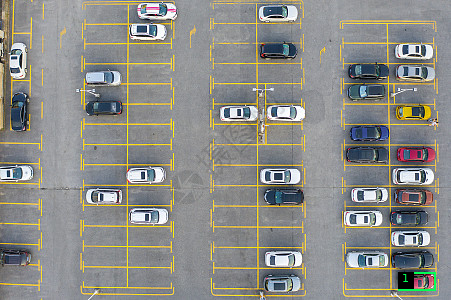

模型原始框数：38 | 去重后：36 | 当前显示：1 | 原始 Mask：0 | 本图显示 Mask：0
说明：为突出题目目标，隐藏了其他已解析框；使用 show_all=True 可显示全部不重复框。
本次模型未生成可解码 Mask（通常没有 <OBJ> 标记）；这不是画图丢失。

Thinking: N/A（标准推理）
模型原始回答（保留结构化 token）：
 <ref>the bottommost red car in the rightmost parking column</ref><box><883><907><965><967></box>, <ref>located at the center of the image</ref><box><883><907><965><967></box>, <ref>the surrounding cars are:</ref><box><0><547><72><607>,<0><831><71><887>,<18><137><62><263>,<23><308><64><436>,<186><231><270><286>,<186><628><270><684>,<188><327><271><383>,<285><555><370><614>,<287><78><370><135>,<287><695><375><753>,<303><7><392><66>,<485><348><570><403>,<576><15><662><75>,<576><140><660><199>,<578><558><666><616>,<581><835><670><891>,<582><913><671><977>,<584><628><674><685>,<590><346><677><403>,<765><702><851><758>,<767><486><861><544>,<767><833><861><893>,<769><278><858><336>,<771><210><860><267>,<775><412><861><469>,<777><623><860><680>,<866><767><955><826>,<867><700><953><758>,<868><558><960><618>,<868

{'status': 'completed',
 'box_count_raw': 38,
 'box_count_unique': 36,
 'box_count_displayed': 1,
 'num_masks': 0,
 'seconds': 8.39,
 'response_chars': 962,
 'history_index': 0}

In [5]:
question = FRAME + """
Find the bottommost red car in the rightmost parking column.

1. Locate the car and report its bounding box and segmentation mask.
2. Describe where it is relative to the CENTER of the image.
3. Describe the surrounding cars and their relative positions.

Answer the descriptions in Chinese.
"""

test(img1, question, thinking=False)

### 测试二——多目标定位
任务：找到图片2中所有明显呈蓝色的汽车，标记每辆车。

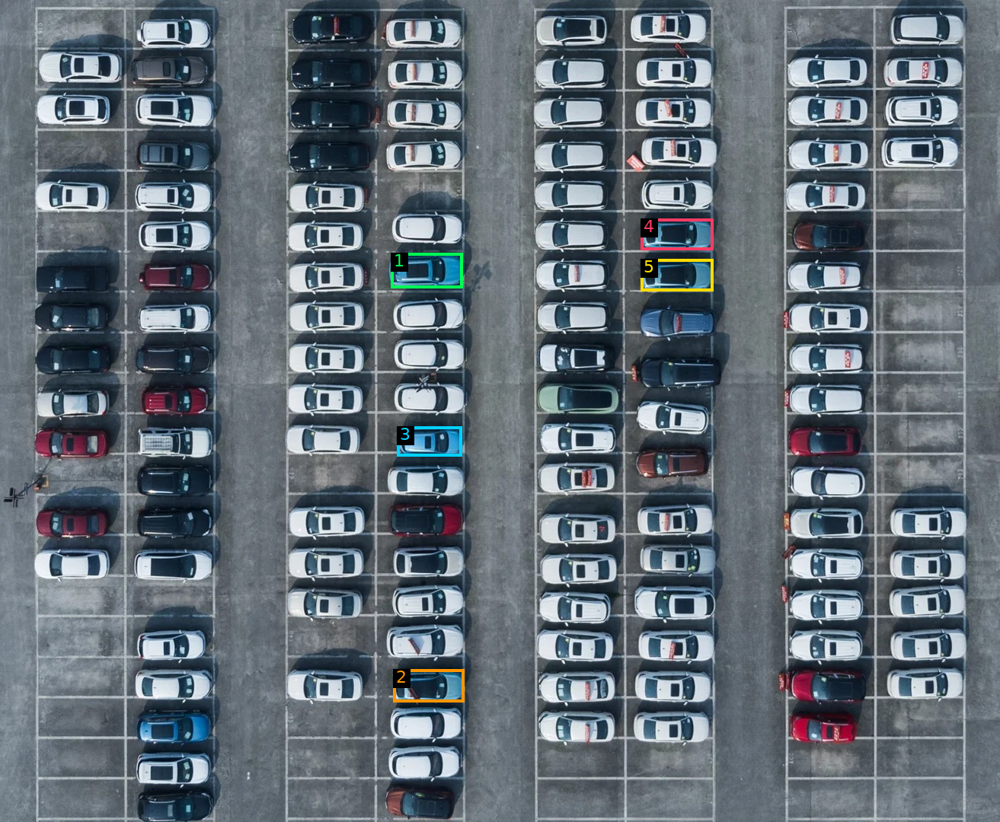

模型原始框数：10 | 去重后：5 | 当前显示：5 | 原始 Mask：0 | 本图显示 Mask：0
本次模型未生成可解码 Mask（通常没有 <OBJ> 标记）；这不是画图丢失。

Thinking: N/A（标准推理）
模型原始回答（保留结构化 token）：
 <ref>cars with visibly blue body paint</ref><box><391><308><463><350>,<393><814><464><854>,<397><519><462><555>,<641><266><713><304>,<641><315><713><354></box>, <ref>For each blue car:</ref><box><391><308><463><350>,<393><814><464><854>,<397><519><462><555>,<641><266><713><304>,<641><315><713><354></box>

推理耗时：2.56 s


{'status': 'completed',
 'box_count_raw': 10,
 'box_count_unique': 5,
 'box_count_displayed': 5,
 'num_masks': 0,
 'seconds': 2.56,
 'response_chars': 305,
 'history_index': 1}

In [6]:
question = FRAME + """
Find ALL cars with visibly blue body paint.
Do not include black or gray cars.

For each blue car:
1. Report its bounding box and segmentation mask.

Answer the descriptions in Chinese.
"""

test(img2, question, thinking=False)

### 测试三——空间比较与极值定位（关闭思考）
任务：在图片2的所有蓝色汽车中，找出画面最靠下的一辆。这里的“下”是相对画面中心而言，而非车辆的驾驶方向。

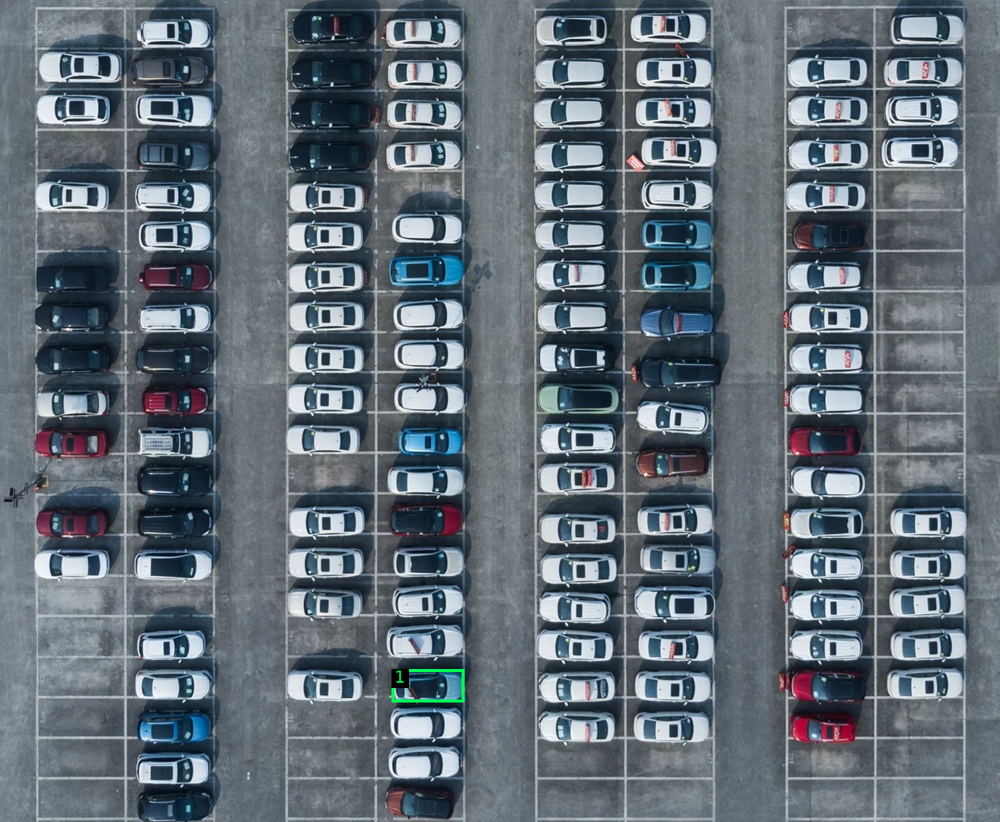

模型原始框数：1 | 去重后：1 | 当前显示：1 | 原始 Mask：0 | 本图显示 Mask：0
本次模型未生成可解码 Mask（通常没有 <OBJ> 标记）；这不是画图丢失。

Thinking: N/A（标准推理）
模型原始回答（保留结构化 token）：
 <ref>The blue car that is located lowest in the image</ref><box><392><814><464><854></box>, positioned at the center of the image.

推理耗时：1.06 s


{'status': 'completed',
 'box_count_raw': 1,
 'box_count_unique': 1,
 'box_count_displayed': 1,
 'num_masks': 0,
 'seconds': 1.06,
 'response_chars': 130,
 'history_index': 2}

In [7]:
question = FRAME + """
Among all visibly blue cars, find the one located lowest in the image.

1. Locate this car and report its bounding box and segmentation mask.
2. Describe its position relative to the CENTER of the image.
3. Explain its relative position compared with the other blue cars.
"""

test(img2, question, thinking=False)

### 测试三——空间比较与极值定位（开启思考）
任务：在图片2的所有蓝色汽车中，找出画面最靠下的一辆。这里的“下”是相对画面中心而言，而非车辆的驾驶方向。

> **注意**：原题和调用形式均保持不变。腾讯官方未提供相应 Thinking 开关，因此 `thinking=True` 会显示 **N/A** 并跳过本轮，不把未运行项算作错误。

In [8]:
question = FRAME + """
Among all visibly blue cars, find the one located lowest in the image.

1. Locate this car and report its bounding box and segmentation mask.
2. Describe its position relative to the CENTER of the image.
3. Explain its relative position compared with the other blue cars.
"""

test(img2, question, thinking=True)

N/A：WeVisOne-VL-4B 官方 API 未提供 enable_thinking 切换。
不修改提示词、不执行推理，也不把此项计作模型失败。


{'status': 'N/A', 'reason': 'thinking switch unsupported'}

### 测试四——多步空间关系推理（关闭思考）
任务：以图片2中部偏右的蓝色汽车 A 为参考，先向画面左侧移动一个停车位列，再向画面上方移动一个停车位行，找到 B。

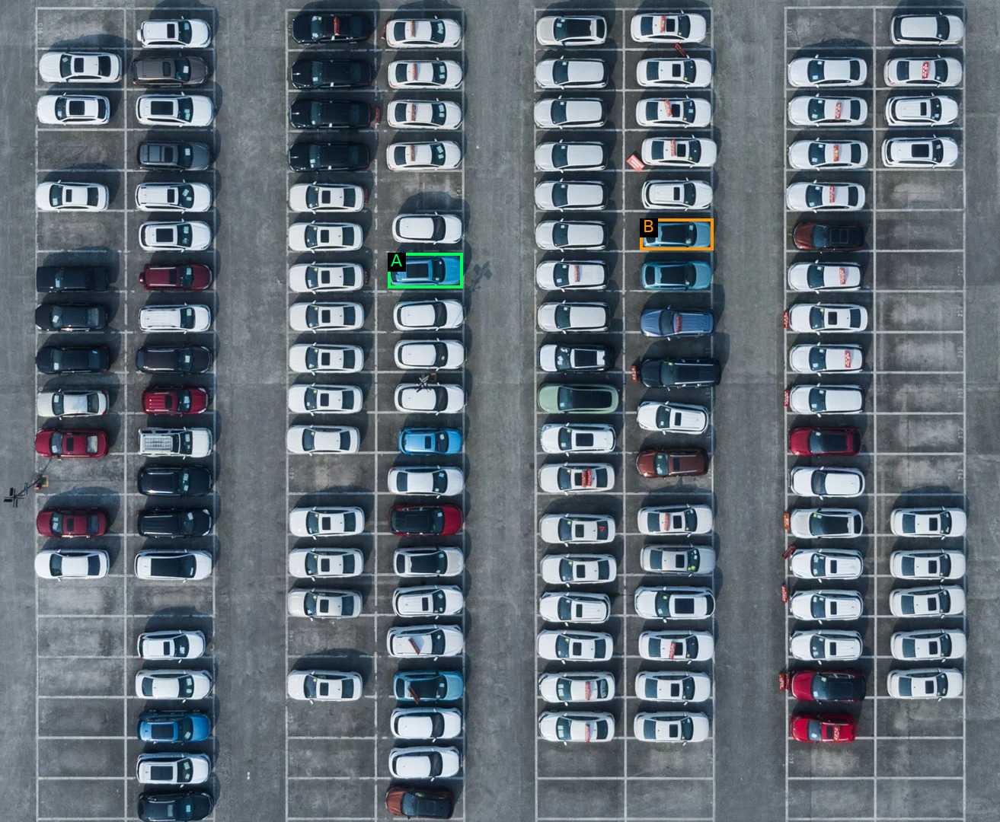

模型原始框数：5 | 去重后：2 | 当前显示：2 | 原始 Mask：0 | 本图显示 Mask：0
说明：A/B 按输出框顺序暂标，必须对照原始回复核实其语义对应关系。
本次模型未生成可解码 Mask（通常没有 <OBJ> 标记）；这不是画图丢失。

Thinking: N/A（标准推理）
模型原始回答（保留结构化 token）：
 <ref>A and B</ref><box><388><308><463><350>,<640><266><713><304></box>, <ref>The color and appearance of car B:</ref><box><388><308><463><350></box>, <ref>B is located to the left of A.</ref><box><388><308><463><350></box>, <ref>B is located to the left of the CENTER of the entire image.</ref><box><388><308><463><350></box>

推理耗时：2.75 s


{'status': 'completed',
 'box_count_raw': 5,
 'box_count_unique': 2,
 'box_count_displayed': 2,
 'num_masks': 0,
 'seconds': 2.75,
 'response_chars': 325,
 'history_index': 3}

In [9]:
question = FRAME + """
In the middle-right area of the image, find the two bright blue cars
parked vertically next to each other.

Call the UPPER blue car A.

Starting from A:
1. Move ONE parking-space column toward IMAGE-LEFT.
2. Then move ONE parking-space row toward IMAGE-UP.
3. Call the car at the destination B.

Tasks:
1. Locate A and B, in that order, using bounding boxes and masks.
2. Describe the color and appearance of car B.
3. Describe where B is relative to A.
4. Describe where B is relative to the CENTER of the entire image.

If there is no car at the destination, state that explicitly.

Answer the descriptions in Chinese.
"""

test(img2, question, labels=["A", "B"], thinking=False)

### 测试四——多步空间关系推理（开启思考）
任务：以图片2中部偏右的蓝色汽车 A 为参考，先向画面左侧移动一个停车位列，再向画面上方移动一个停车位行，找到 B。

> **注意**：原题和调用形式均保持不变。腾讯官方未提供相应 Thinking 开关，因此 `thinking=True` 会显示 **N/A** 并跳过本轮，不把未运行项算作错误。

In [10]:
question = FRAME + """
In the middle-right area of the image, find the two bright blue cars
parked vertically next to each other.

Call the UPPER blue car A.

Starting from A:
1. Move ONE parking-space column toward IMAGE-LEFT.
2. Then move ONE parking-space row toward IMAGE-UP.
3. Call the car at the destination B.

Tasks:
1. Locate A and B, in that order, using bounding boxes and masks.
2. Describe the color and appearance of car B.
3. Describe where B is relative to A.
4. Describe where B is relative to the CENTER of the entire image.

If there is no car at the destination, state that explicitly.

Answer the descriptions in Chinese.
"""

test(img2, question, labels=["A", "B"], thinking=True)

N/A：WeVisOne-VL-4B 官方 API 未提供 enable_thinking 切换。
不修改提示词、不执行推理，也不把此项计作模型失败。


{'status': 'N/A', 'reason': 'thinking switch unsupported'}

总体评价：模型具备较好的基础目标定位能力，推理输出较为稳定，但在复杂场景中存在明显漏检，全局空间比较与多步空间推理能力不足。此外，模型对提示词和任务格式的适应性较差。

一、各项测试结果

① 单目标定位	基本成功	成功定位右下角目标红车，BBox 基本准确。但错误地将目标描述为位于图像中心，且输出大量无关车辆框。

② 多目标定位	部分成功	原始输出10个框，去重后仅5辆蓝车。已定位目标基本正确，但遗漏左侧下方多辆明显的蓝车，存在较严重漏检。

③ 空间比较与极值定位	失败	找到了靠近下方的蓝车，但并非全图最下方的蓝车；同时错误地将其描述为位于图像中心。

④ 多步空间关系推理	失败	能定位两个相关区域的车辆，但没有正确完成“左移一列、上移一行”的操作。输出中 B 位于 A 左下方，而非要求的左上方，且缺少有效的车辆外观描述。

二、值得关注的现象

1. 目标定位能力较好，但不代表空间理解能力强。
模型能够快速输出较准确的车辆 BBox，但对于目标相对图像中心的位置、车辆之间的空间关系等问题，依然会出现明显错误。
尤其是测试一、三，视觉框基本能够对应目标，但文字方位描述却明显不正确，说明目标定位能力与空间关系理解能力存在差距。

2. 全局感知能力仍然不足。
测试二只识别出5辆蓝车，遗漏了多个明显目标。测试三进一步暴露出问题：模型选中的蓝车并非全图位置最低的蓝车。
这表明模型虽然能够定位局部目标，但难以保证全局搜索的完整性，从而影响后续空间比较结果。

3. 输出高度依赖任务格式。
四项正式测试均未输出 Mask，仅返回 BBox，部分任务还没有按照要求生成中文描述。
但是，使用腾讯官方原生 segmentation 模板后，模型成功生成了1个红车 Mask 和5个蓝车 Mask。
这说明模型具备像素级分割能力，但在自由形式的复杂指令下，未能可靠调用该能力。因此，正式测试的 Mask 缺失不能直接归因于视觉感知能力不足。

4. 推理较为稳定，但复杂空间推理仍然不可靠。
与 Qwen3.5-4B 在复杂任务中出现的重复生成、Token 耗尽等现象不同，腾讯模型的四项实际推理均正常结束，没有出现明显的生成失控问题。
不过，输出稳定并不等于结果正确，尤其是多步空间推理任务依然失败。

三、核心结论
1. 基础视觉定位能力较好。 模型能够识别并输出较准确的车辆 BBox，但密集场景中存在明显漏检。
2. 空间理解与推理能力不足。 简单目标定位可以完成，但全局极值比较、多步位置变换以及图像中心参考系下的方位判断均不可靠。
3. 视觉感知与语言空间描述存在脱节。 模型能够输出正确或接近正确的定位框，却不能始终正确描述对应的空间关系。
4. 任务适配性问题突出。 使用官方专用模板可以生成 Mask，但相同的复杂自由指令无法稳定触发这一能力。
5. 与 Xiaomi-Lens-0、Qwen3.5-4B 相比，腾讯模型在本次测试中表现出较好的生成稳定性，但没有展现出可靠的复杂空间推理能力。 另外，腾讯模型不支持本次实验所需的 Thinking 开关，因此不能进行相同条件下的 Thinking 对比。

四、最终判断

WeVisOne-VL-4B 更擅长“找到目标在哪里”，而不擅长“理解目标之间的复杂空间关系”。

它的目标定位和分割能力具有一定优势，但这种优势尚未有效转化为复杂场景中的全局空间理解和多步推理能力。

对后续 VLA/VLN 研究的启示： 三个模型的测试共同暴露出一个值得关注的问题：较强的视觉感知能力，并不必然带来可靠的空间推理能力。 如何让模型从准确感知目标进一步发展到理解目标间的空间关系，可能是比单纯提高目标检测精度更值得研究的方向。

注：以上属于两张停车场图像上的小规模定性测试结论，不能代表模型整体性能。腾讯官方原生分割诊断使用了不同提示词，不计入三模型的直接对比。

### 可选：腾讯官方原生任务的独立诊断（**不计入上述对比**）

如果原样输入的多目标题没有返回 Mask，可用官方 `segmentation` 任务验证 Mask 解码器确实能够工作。**注意此测试使用腾讯原生模板，提示词与前两模型不再一致，绝不能将结果混入正式表格。**

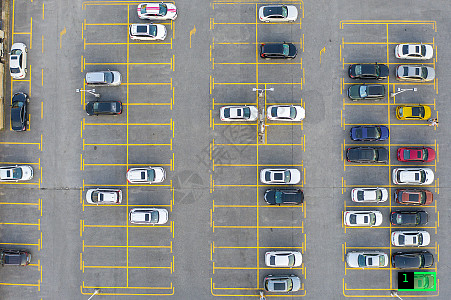

模型原始框数：2 | 去重后：1 | 当前显示：1 | 原始 Mask：1 | 本图显示 Mask：1
原生任务红车 Mask 数: 1


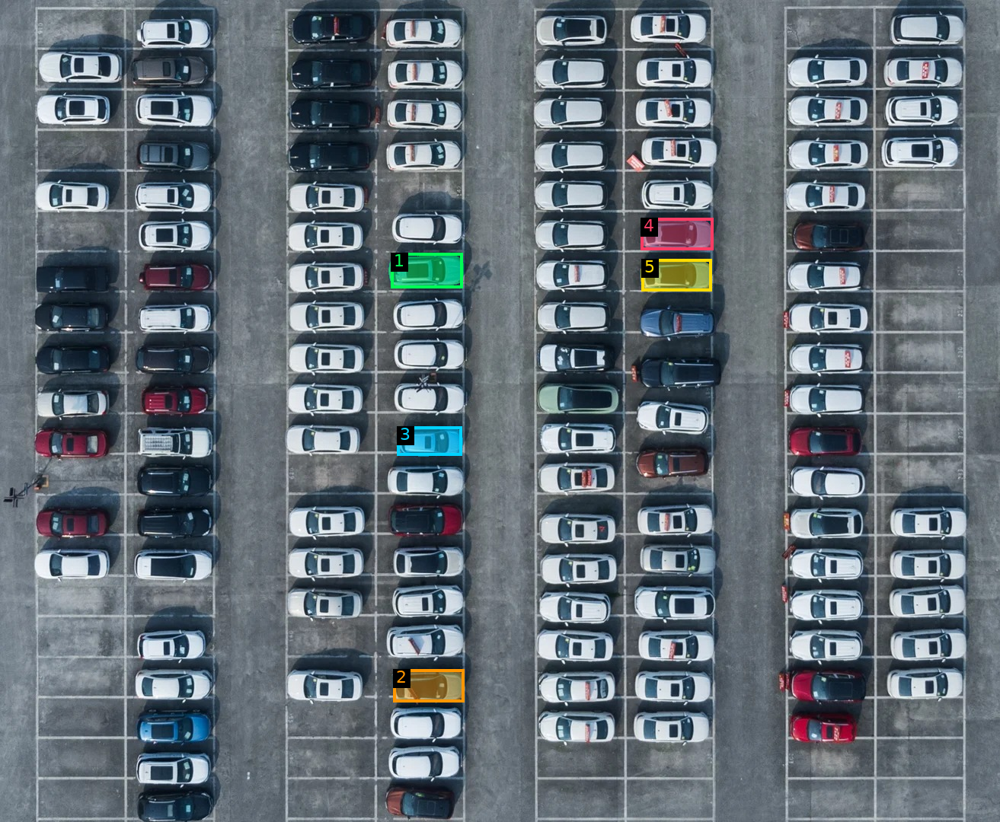

模型原始框数：10 | 去重后：5 | 当前显示：5 | 原始 Mask：5 | 本图显示 Mask：5
原生任务蓝车 Mask 数: 5


In [12]:
# 可选诊断：这两项不计入三模型相同提示词比较。
# 原因：腾讯原生 segmentation 会使用自己的任务模板，不能与 freeform 原题混算。
# 在正式测试运行完后，如要验证 Mask 解码链路，可单独运行：

native_red = model.predict(
    img1, task="segmentation",
    query="the bottommost red car in the rightmost parking column",
    temperature=0.0, max_new_tokens=2048,
)
_display_result(img1, native_red, _records_from_result(img1, native_red),
                question="find all cars", show_all=True)
print("原生任务红车 Mask 数:", len(native_red.masks))

native_blue = model.predict(
    img2, task="segmentation", query="visibly blue cars",
    temperature=0.0, max_new_tokens=2048,
)
_display_result(img2, native_blue, _records_from_result(img2, native_blue),
                question="find all cars", show_all=True)
print("原生任务蓝车 Mask 数:", len(native_blue.masks))
